In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
PATH = "../../ddos_dataset.csv"
df = pd.read_csv(PATH, index_col=0, low_memory=False)
df.head(10)


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,SimillarHTTP,Inbound,label
0,172.16.0.5-192.168.50.1-634-60495-17,172.16.0.5,634,192.168.50.1,60495,17,2018-12-01 10:51:39.813448,28415,97,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
1,172.16.0.5-192.168.50.1-60495-634-17,192.168.50.1,634,172.16.0.5,60495,17,2018-12-01 10:51:39.820842,2,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,ddos_dns
2,172.16.0.5-192.168.50.1-634-46391-17,172.16.0.5,634,192.168.50.1,46391,17,2018-12-01 10:51:39.852499,48549,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
3,172.16.0.5-192.168.50.1-634-11894-17,172.16.0.5,634,192.168.50.1,11894,17,2018-12-01 10:51:39.890213,48337,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
4,172.16.0.5-192.168.50.1-634-27878-17,172.16.0.5,634,192.168.50.1,27878,17,2018-12-01 10:51:39.941151,32026,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
5,172.16.0.5-192.168.50.1-634-47149-17,172.16.0.5,634,192.168.50.1,47149,17,2018-12-01 10:51:39.942030,46469,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
6,172.16.0.5-192.168.50.1-634-22713-17,172.16.0.5,634,192.168.50.1,22713,17,2018-12-01 10:51:39.973650,31201,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
7,172.16.0.5-192.168.50.1-634-49912-17,172.16.0.5,634,192.168.50.1,49912,17,2018-12-01 10:51:39.994394,50453,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
8,172.16.0.5-192.168.50.1-634-56681-17,172.16.0.5,634,192.168.50.1,56681,17,2018-12-01 10:51:40.005191,31008,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
9,172.16.0.5-192.168.50.1-634-13161-17,172.16.0.5,634,192.168.50.1,13161,17,2018-12-01 10:51:40.036581,30143,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns


In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 64239 entries, 0 to 65999
Data columns (total 87 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Flow ID                       64239 non-null  str    
 1    Source IP                    64239 non-null  str    
 2    Source Port                  64239 non-null  int64  
 3    Destination IP               64239 non-null  str    
 4    Destination Port             64239 non-null  int64  
 5    Protocol                     64239 non-null  int64  
 6    Timestamp                    64239 non-null  str    
 7    Flow Duration                64239 non-null  int64  
 8    Total Fwd Packets            64239 non-null  int64  
 9    Total Backward Packets       64239 non-null  int64  
 10  Total Length of Fwd Packets   64239 non-null  float64
 11   Total Length of Bwd Packets  64239 non-null  float64
 12   Fwd Packet Length Max        64239 non-null  float64
 13   Fwd Packet Lengt

In [15]:
df.columns = df.columns.str.strip().str.replace(" ", "_")
df = df.rename(columns={"SimmilarHTTP":"SimilarHTTP"})
df

,Flow_ID,Source_IP,Source_Port,Destination_IP,Destination_Port,Protocol,Timestamp,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,...,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,SimillarHTTP,Inbound,label
0,172.16.0.5-192.168.50.1-634-60495-17,172.16.0.5,634,192.168.50.1,60495,17,2018-12-01 10:51:39.813448,28415,97,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
1,172.16.0.5-192.168.50.1-60495-634-17,192.168.50.1,634,172.16.0.5,60495,17,2018-12-01 10:51:39.820842,2,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,ddos_dns
2,172.16.0.5-192.168.50.1-634-46391-17,172.16.0.5,634,192.168.50.1,46391,17,2018-12-01 10:51:39.852499,48549,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
3,172.16.0.5-192.168.50.1-634-11894-17,172.16.0.5,634,192.168.50.1,11894,17,2018-12-01 10:51:39.890213,48337,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
4,172.16.0.5-192.168.50.1-634-27878-17,172.16.0.5,634,192.168.50.1,27878,17,2018-12-01 10:51:39.941151,32026,200,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_dns
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65995,172.16.0.5-192.168.50.1-38625-63051-17,172.16.0.5,38625,192.168.50.1,63051,17,2018-12-01 13:04:46.628249,1,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_udp_lag
65996,172.16.0.5-192.168.50.1-58632-18963-17,172.16.0.5,58632,192.168.50.1,18963,17,2018-12-01 13:04:46.628963,212238,6,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_udp_lag
65997,172.16.0.5-192.168.50.1-46104-64704-17,172.16.0.5,46104,192.168.50.1,64704,17,2018-12-01 13:04:46.629014,1,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_udp_lag
65998,172.16.0.5-192.168.50.1-60686-10440-17,172.16.0.5,60686,192.168.50.1,10440,17,2018-12-01 13:04:46.629016,108952,4,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1,ddos_udp_lag


In [44]:
df.loc[(df["SYN_Flag_Count"] == 0) & (df["label"] == "ddos_syn")]

,Flow_ID,Source_IP,Source_Port,Destination_IP,Destination_Port,Protocol,Timestamp,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,...,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,SimillarHTTP,Inbound,label
48000,172.16.0.5-192.168.50.1-53058-53058-6,172.16.0.5,53058,192.168.50.1,53058,6,2018-12-01 13:30:30.741451,115799309,19,2,...,646237.483665,1709809.0,1.0,1.426117e+07,3.220326e+06,21714933.0,11043464.0,0,1,ddos_syn
48001,172.16.0.5-192.168.50.1-32237-32237-6,172.16.0.5,32237,192.168.50.1,32237,6,2018-12-01 13:30:30.741452,113973933,16,0,...,19.595918,49.0,1.0,1.628198e+07,2.573891e+06,20019405.0,11993631.0,0,1,ddos_syn
48002,172.16.0.5-192.168.50.1-60495-9840-6,172.16.0.5,60495,192.168.50.1,9840,6,2018-12-01 13:30:30.741501,112,2,2,...,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,ddos_syn
48003,172.16.0.5-192.168.50.1-59724-59724-6,172.16.0.5,59724,192.168.50.1,59724,6,2018-12-01 13:30:30.741563,105985004,16,0,...,17.705259,48.0,1.0,1.514071e+07,3.077366e+06,20954123.0,11120336.0,0,1,ddos_syn
48004,172.16.0.5-192.168.50.1-60496-32538-6,172.16.0.5,60496,192.168.50.1,32538,6,2018-12-01 13:30:30.741565,1,2,0,...,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,ddos_syn
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53993,172.16.0.5-192.168.50.1-21715-21715-6,172.16.0.5,21715,192.168.50.1,21715,6,2018-12-01 13:30:31.346386,112185181,10,0,...,23.837995,49.0,1.0,2.804627e+07,1.279721e+07,44411696.0,15312041.0,0,1,ddos_syn
53996,172.16.0.5-192.168.50.1-64025-17839-6,172.16.0.5,64025,192.168.50.1,17839,6,2018-12-01 13:30:31.346501,1,2,0,...,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,ddos_syn
53997,172.16.0.5-192.168.50.1-64026-8133-6,172.16.0.5,64026,192.168.50.1,8133,6,2018-12-01 13:30:31.346943,1,2,0,...,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,ddos_syn
53998,172.16.0.5-192.168.50.1-64027-59735-6,172.16.0.5,64027,192.168.50.1,59735,6,2018-12-01 13:30:31.347063,1,2,0,...,0.000000,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0,1,ddos_syn


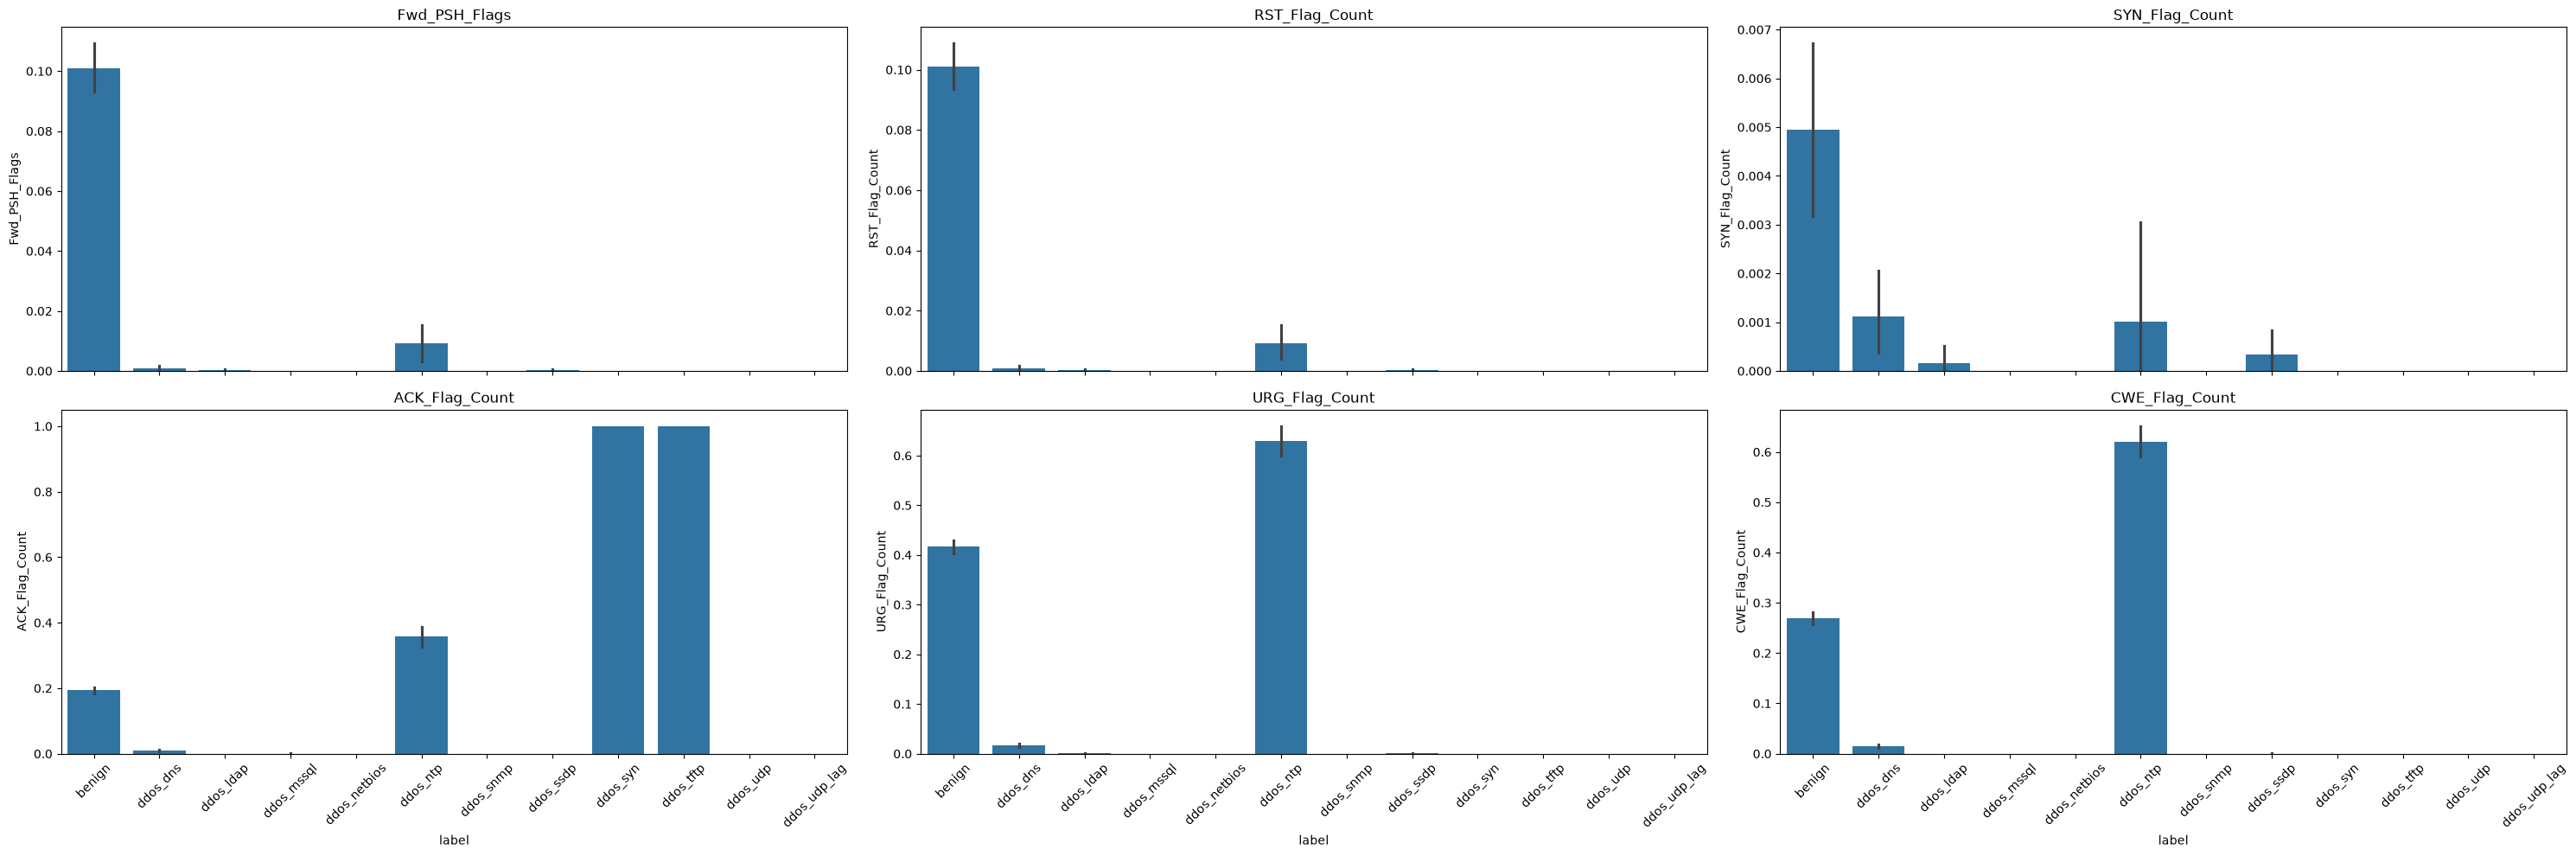

In [81]:
import math
counting_features = ["Fwd_PSH_Flags", "RST_Flag_Count", "SYN_Flag_Count", "ACK_Flag_Count", "URG_Flag_Count", "CWE_Flag_Count"]
labels = list(set(df["label"].values))
order = sorted(labels)

fig, axes = plt.subplots(2, 3, figsize=(30, 10), sharex=True)   

for ax, feature in zip(axes.flat, counting_features):
    sns.barplot(df, x="label", y=feature, order=order, ax=ax)
    ax.tick_params(axis="x", rotation=45)
    ax.set_title(feature)

for ax in axes.flat[len(counting_features):]:
    ax.axis("off")

plt.tight_layout()                              
plt.show()

Apparently:
- Fwd_PSH_Flags == RST_Flag_Count (it's the same feature)

In [104]:
LABELS = sorted(list(set(df["label"].values)))
df.groupby("label")["Protocol"].value_counts().reindex(LABELS)

benign         NaN
ddos_dns       NaN
ddos_ldap      NaN
ddos_mssql     NaN
ddos_netbios   NaN
ddos_ntp       NaN
ddos_snmp      NaN
ddos_ssdp      NaN
ddos_syn       NaN
ddos_tftp      NaN
ddos_udp       NaN
ddos_udp_lag   NaN
Name: count, dtype: float64

In [112]:
prot_crosstab = pd.crosstab(df.label, df.Protocol, normalize="index")
prot_crosstab

Protocol,0,6,17
label,,,
benign,0.007070,0.610463,0.382467
ddos_dns,0.000745,0.026448,0.972807
ddos_ldap,0.000169,0.000337,0.999494
ddos_mssql,0.000169,0.000169,0.999662
ddos_netbios,0.000172,0.000000,0.999828
ddos_ntp,0.007099,0.986815,0.006085
ddos_snmp,0.000000,0.000000,1.000000
ddos_ssdp,0.000168,0.000503,0.999330
ddos_syn,0.000182,0.999818,0.000000


The table above shows TCP flows inside UDP attacks

In [130]:
# check
print((df["Fwd_PSH_Flags"] == df["RST_Flag_Count"]).all())
print((df["Fwd_Header_Length"] == df["Fwd_Header_Length.1"]).all())

True
True


- Fwd_PSH_Flags and RST_Flag_Count are the same features, so we can remove one of them for sure.

POTREMMO USARE I RECORD CON PROTOCOL = 0 PER IL VALIDATION TEST PERCHÉ = 0 VUOL DIRE CHE LO STRUMENTO CICFLOWMETER NON È RIUSCITO A RILEVARE IL PROTOCOLLO

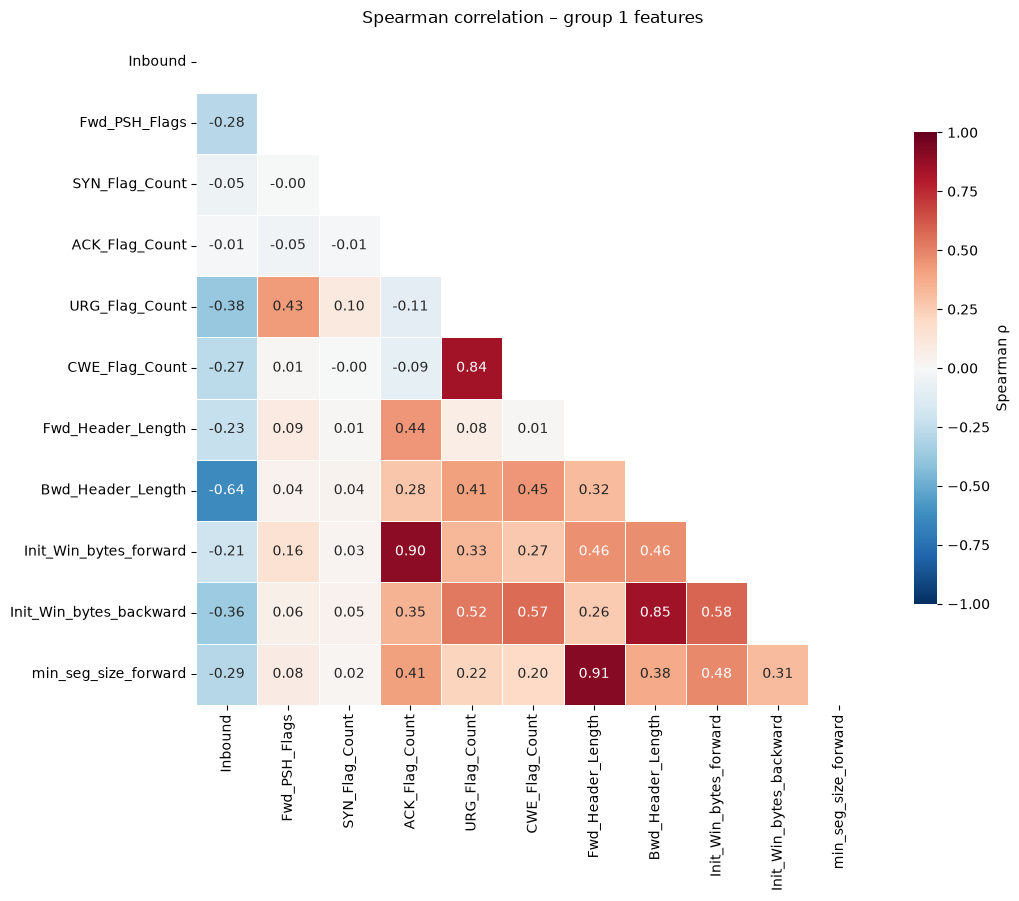

In [122]:
group_features = ["Inbound", "Fwd_PSH_Flags", "SYN_Flag_Count", "ACK_Flag_Count", "URG_Flag_Count",
                  "CWE_Flag_Count", "Fwd_Header_Length", "Bwd_Header_Length",
                  "Init_Win_bytes_forward", "Init_Win_bytes_backward", "min_seg_size_forward"]

corr = df[group_features].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))    

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Spearman correlation – group 1 features")
plt.tight_layout(); plt.show()

I'm using spearman instead of pearson also because spearman is less sensitive to few outliers

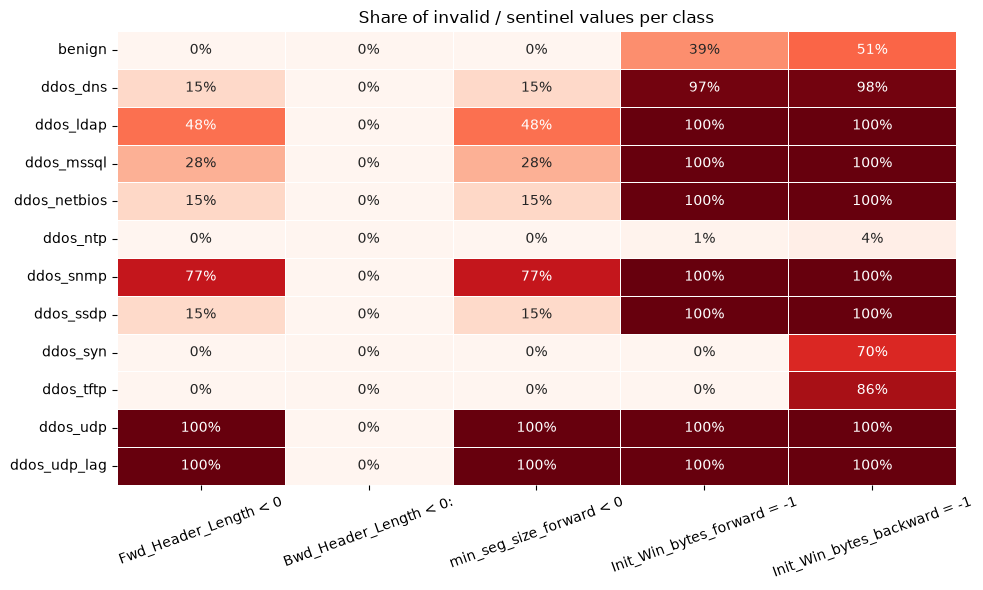

In [117]:
invalid = pd.DataFrame({
    "Fwd_Header_Length < 0":        df["Fwd_Header_Length"] < 0,
    "Bwd_Header_Length < 0:":       df["Bwd_Header_Length"] < 0,
    "min_seg_size_forward < 0":     df["min_seg_size_forward"] < 0,
    "Init_Win_bytes_forward = -1":  df["Init_Win_bytes_forward"] == -1,
    "Init_Win_bytes_backward = -1": df["Init_Win_bytes_backward"] == -1,
}).groupby(df["label"]).mean().reindex(LABELS)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(invalid, annot=True, fmt=".0%", cmap="Reds", vmin=0, vmax=1, cbar=False, linewidths=.5, ax=ax)
ax.set_title("Share of invalid / sentinel values per class")
ax.set_ylabel(""); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

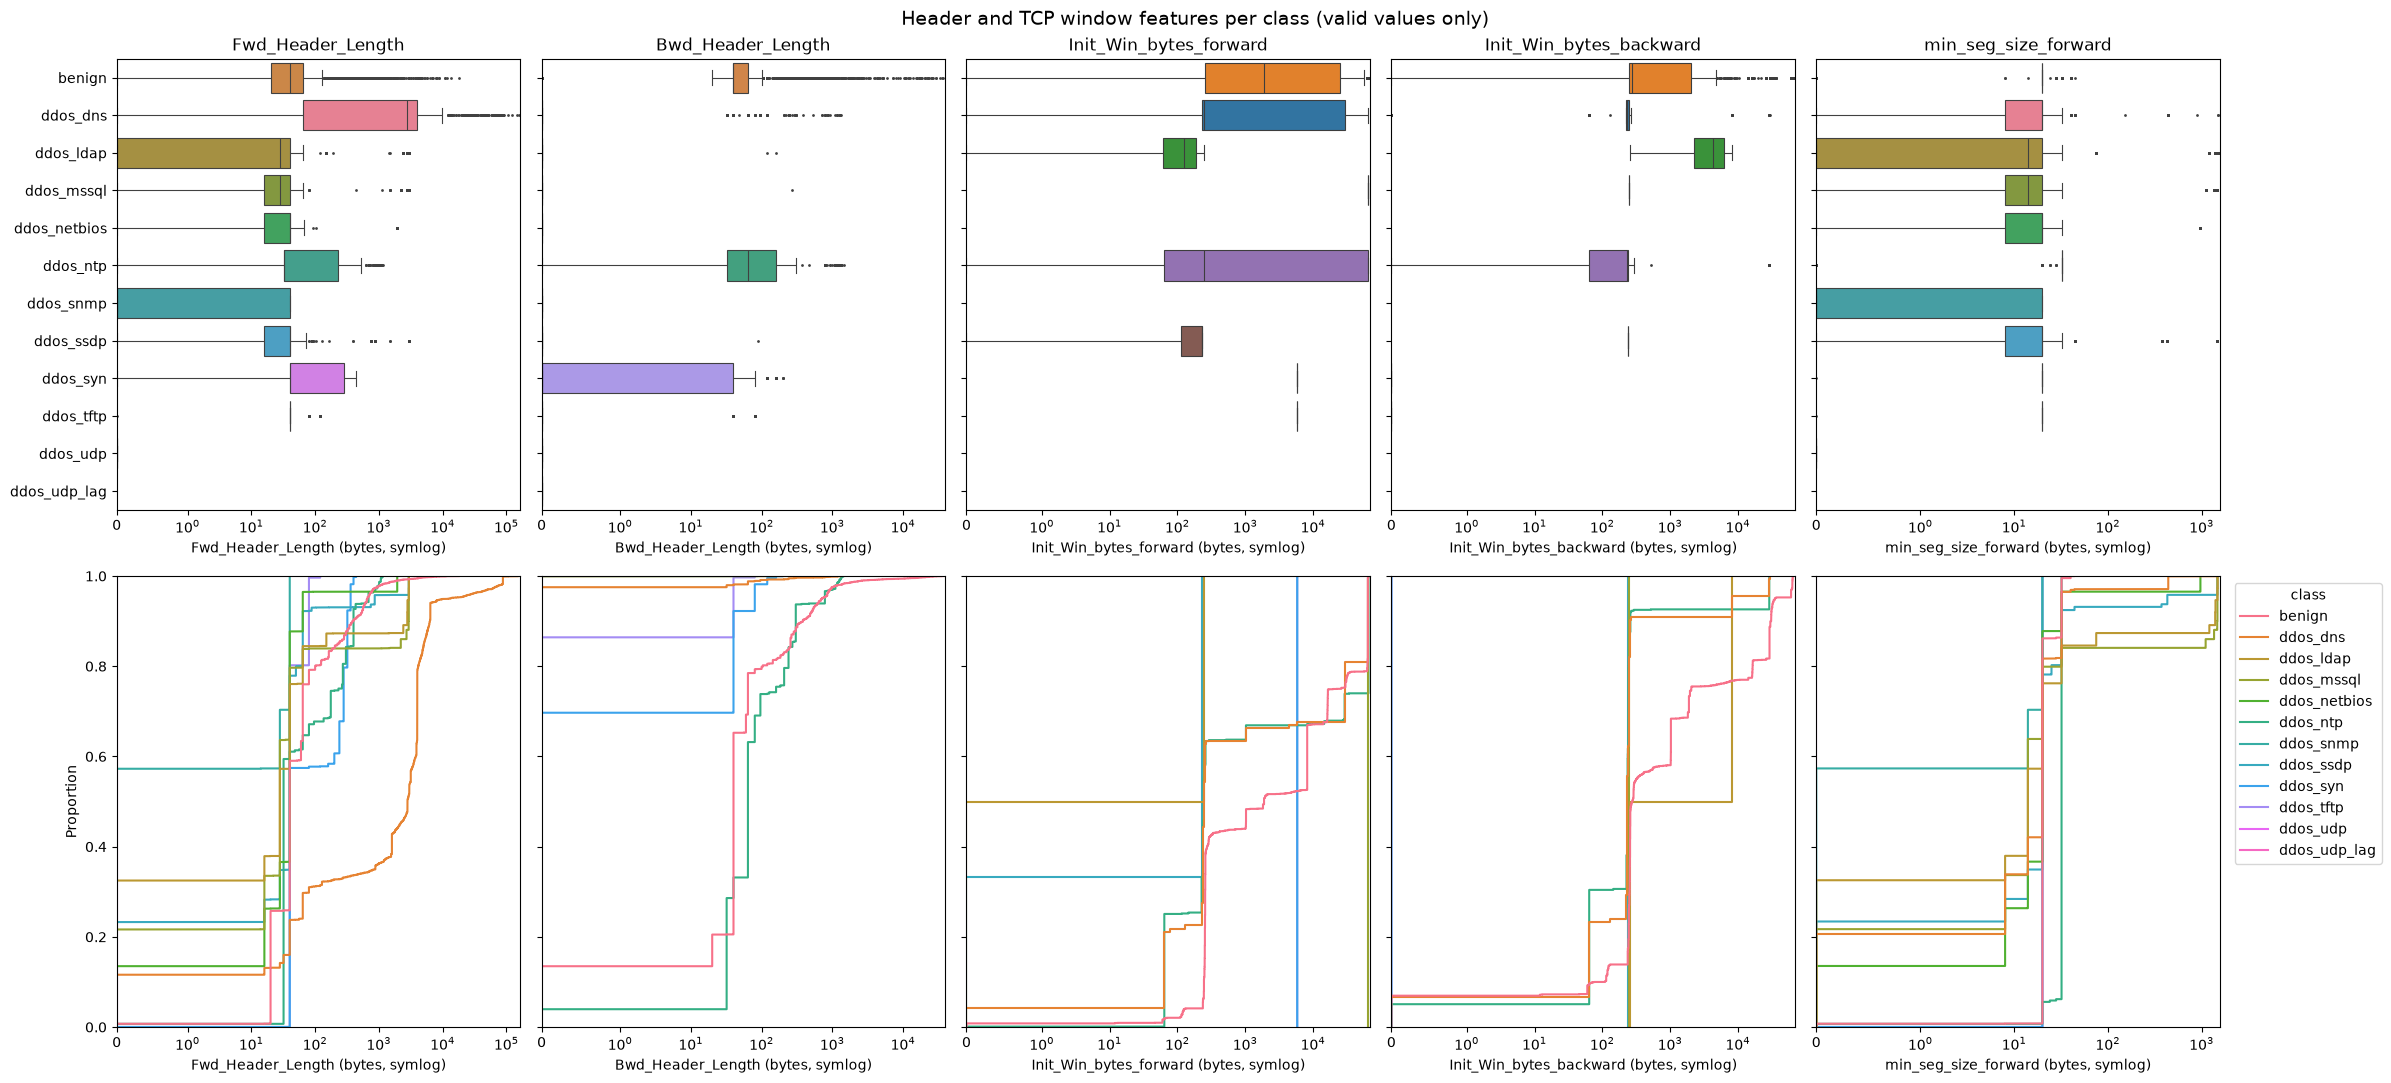

In [ ]:
# per-class distribution

size_features = ["Fwd_Header_Length", "Bwd_Header_Length", "Init_Win_bytes_forward",
                 "Init_Win_bytes_backward", "min_seg_size_forward"]

fig, axes = plt.subplots(2, len(size_features), figsize=(24, 11), sharey="row")

for j, feature in enumerate(size_features):
    valid = df[df[feature] >= 0]
    sns.boxplot(data=valid, x=feature, y="label", order=LABELS, hue="label",
                legend=False, fliersize=1, linewidth=.8, ax=axes[0, j])
    sns.ecdfplot(data=valid, x=feature, hue="label", hue_order=LABELS,
                 legend=(j == len(size_features) - 1), ax=axes[1, j])
    for ax in axes[:, j]:
        ax.set_xscale("symlog", linthresh=1)
        ax.set_xlim(left=0)
        ax.set_xlabel(f"{feature} (bytes, symlog)")
    axes[0, j].set_title(feature)
    axes[0, j].set_ylabel("")

sns.move_legend(axes[1, -1], "upper left", bbox_to_anchor=(1.02, 1), title="class")
fig.suptitle("Header and TCP window features per class (valid values only)", fontsize=14)
plt.tight_layout(); plt.show()

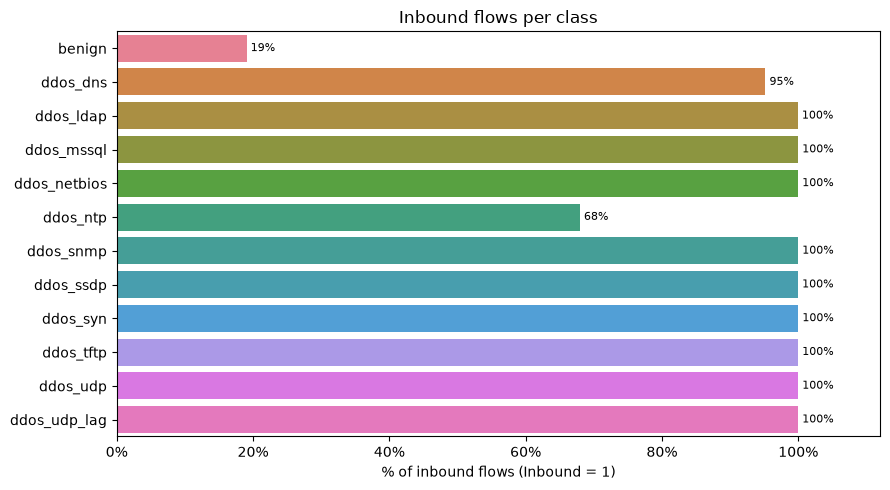

In [124]:
# per-class inbound
inbound = df.groupby("label")["Inbound"].mean().reindex(LABELS)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=inbound.values, y=inbound.index, hue=inbound.index, legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt=lambda v: f"{v:.0%}", padding=3, fontsize=8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, 1.12)
ax.set_xlabel("% of inbound flows (Inbound = 1)"); ax.set_ylabel("")
ax.set_title("Inbound flows per class")
plt.tight_layout(); plt.show()

To do con tutte le altre features:
- eliminare RST_Flag_Count e Fwd_Header_Length.1

Correlazioni:
- Init_Win_Bytes_forward <-> ACK_Flag_Count
- Init_Win_Bytes_backward <-> Bwd_Header_Length
- min_seg_size_forward <-> Fwd_Header_Length
- CWE_Flag_Count <-> URG_Flag_Count